In [1]:
# Imports
# ============================================================
import numpy as np
import time
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from torchvision import datasets
import random

# Load MNIST
# ============================================================
train_dataset_full = datasets.MNIST(root='./data', train=True,  download=True)
test_dataset_full  = datasets.MNIST(root='./data', train=False, download=True)

train_images_full = train_dataset_full.data.numpy()
train_labels_full = train_dataset_full.targets.numpy()
test_images_full  = test_dataset_full.data.numpy()
test_labels_full  = test_dataset_full.targets.numpy()

print(f"Train: {train_images_full.shape}, Test: {test_images_full.shape}")
# Helper functions (subsample + normalize + display)
# ============================================================
def balanced_subsample(images, labels, samples_per_class):
    imgs, labs = [], []
    for digit in range(10):
        idx    = np.where(labels == digit)[0]
        chosen = np.random.choice(idx, samples_per_class, replace=False)
        imgs.append(images[chosen])
        labs.append(labels[chosen])
    return np.vstack(imgs), np.hstack(labs)

def normalize(images):
    # [0,255] → [-1,1]  — MUST match tanh output of generator
    return (images.astype(np.float32) / 127.5) - 1.0

def denormalize(images):
    # [-1,1] → [0,1]  — for display and classifier input
    return (images + 1.0) / 2.0
    
def normalize_clf(images):
    """[0,255] → [0,1] for classifier input"""
    return images.astype(np.float32) / 255.0

def show_samples(images, labels, n=6):
    idx = random.sample(range(len(images)), n)
    plt.figure(figsize=(n * 2, 2))
    for i, j in enumerate(idx):
        plt.subplot(1, n, i + 1)
        plt.imshow(images[j], cmap='gray')
        plt.title(f"Label: {labels[j]}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()

2026-05-11 12:04:54.885788: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778501095.037584      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778501095.080169      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1778501095.428585      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778501095.428649      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778501095.428659      57 computation_placer.cc:177] computation placer alr

Train: (60000, 28, 28), Test: (10000, 28, 28)


In [2]:
# ============================================================
#  NEW: Data augmentation (10-20x)
# Required by assignment before training the GAN
# ============================================================
def augment_dataset(images, labels, augment_factor=15):
    """
    Augment images using rotations, shifts, scaling, and noise.
    augment_factor: how many augmented copies per real image (10-20x).
    Returns original + augmented combined.
    """
    from tensorflow.keras.preprocessing.image import ImageDataGenerator

    datagen = ImageDataGenerator(
        rotation_range=12,          # rotate up to ±12 degrees
        width_shift_range=0.12,     # shift left/right up to 12%
        height_shift_range=0.12,    # shift up/down up to 12%
        zoom_range=0.1,             # scale ±10%
        fill_mode='nearest'
    )

    aug_imgs, aug_labs = [], []

    for digit in range(10):
        digit_imgs = images[labels == digit]           # (350, 28, 28)
        digit_imgs_4d = digit_imgs[..., np.newaxis]    # (350, 28, 28, 1)
        count = 0
        for batch in datagen.flow(digit_imgs_4d, batch_size=len(digit_imgs), shuffle=True):
            aug_imgs.append(batch[:, :, :, 0])         # back to (N, 28, 28)
            aug_labs.append(np.full(len(digit_imgs), digit))
            count += 1
            if count >= augment_factor:
                break

    aug_imgs = np.vstack(aug_imgs)
    aug_labs = np.hstack(aug_labs)

    # Combine real + augmented
    combined_imgs = np.vstack([images, aug_imgs])
    combined_labs = np.hstack([labels, aug_labs])

    print(f"Original: {images.shape[0]} | Augmented: {aug_imgs.shape[0]} | "
          f"Total: {combined_imgs.shape[0]}")
    return combined_imgs, combined_labs

In [3]:
# ============================================================
# Subsample 350 real, then augment
# ============================================================
N_REAL = 350

train_images_350, train_labels_350 = balanced_subsample(train_images_full, train_labels_full, N_REAL)

print(f"Real subset: {train_images_350.shape}")

# Augment 15x → ~5250 augmented + 3500 real = ~8750 total
train_images_aug, train_labels_aug = augment_dataset(
    train_images_350, train_labels_350, augment_factor=15)

# Clip values to [0,255] after augmentation
train_images_aug = np.clip(train_images_aug, 0, 255)

print(f"\nDistribution after augmentation:")
for d in range(10):
    print(f"  Digit {d}: {np.sum(train_labels_aug == d)}")

Real subset: (3500, 28, 28)
Original: 3500 | Augmented: 52500 | Total: 56000

Distribution after augmentation:
  Digit 0: 5600
  Digit 1: 5600
  Digit 2: 5600
  Digit 3: 5600
  Digit 4: 5600
  Digit 5: 5600
  Digit 6: 5600
  Digit 7: 5600
  Digit 8: 5600
  Digit 9: 5600


In [4]:
# ============================================================
#  Build TF dataset for GAN training
# Uses augmented data (normalized to [-1,1] for tanh)
# ============================================================
BATCH_SIZE  = 64
NOISE_DIM   = 100
NUM_CLASSES = 10

# GAN trains on augmented + real data
train_norm = normalize(train_images_aug)[..., np.newaxis]  # (N,28,28,1)

dataset = tf.data.Dataset.from_tensor_slices(
    (train_norm, train_labels_aug.astype(np.int32))
).shuffle(len(train_images_aug)).batch(BATCH_SIZE)

print(f"Batches per epoch: {len(dataset)}")

Batches per epoch: 875


I0000 00:00:1778501189.389142      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1778501189.395044      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [5]:
import tensorflow as tf
from tensorflow.keras import layers

# ============================================================
# CELL 6 — Build CGAN models (Generator + Discriminator)
# ============================================================
def build_generator():
    noise_in = tf.keras.Input(shape=(NOISE_DIM,), name="noise")
    label_in = tf.keras.Input(shape=(1,), dtype=tf.int32, name="label")

    label_emb = layers.Embedding(NUM_CLASSES, 50)(label_in)
    label_emb = layers.Flatten()(label_emb)
    x = layers.Concatenate()([noise_in, label_emb])

    x = layers.Dense(7 * 7 * 256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Reshape((7, 7, 256))(x)

    x = layers.Conv2DTranspose(128, (5,5), strides=(1,1), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2DTranspose(64, (5,5), strides=(2,2), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    output = layers.Conv2DTranspose(
        1, (5,5), strides=(2,2), padding='same',
        use_bias=False, activation='tanh')(x)   # output in [-1,1]

    return tf.keras.Model([noise_in, label_in], output, name="Generator")


def build_discriminator():
    img_in   = tf.keras.Input(shape=(28, 28, 1), name="image")
    label_in = tf.keras.Input(shape=(1,), dtype=tf.int32, name="label")

    label_emb = layers.Embedding(NUM_CLASSES, 50)(label_in)
    label_emb = layers.Dense(28 * 28)(label_emb)
    label_emb = layers.Reshape((28, 28, 1))(label_emb)
    x = layers.Concatenate()([img_in, label_emb])   # (28,28,2)

    x = layers.Conv2D(64,  (5,5), strides=(2,2), padding='same')(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv2D(128, (5,5), strides=(2,2), padding='same')(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Flatten()(x)
    output = layers.Dense(1)(x)   # raw logits

    return tf.keras.Model([img_in, label_in], output, name="Discriminator")


generator     = build_generator()
discriminator = build_discriminator()
generator.summary()
discriminator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ label (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 50)     │        500 │ label[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ noise (InputLayer)  │ (None, 100)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 50)        │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 150)       │          0 │ noise[0][0],      │
│ (Concatenate)       │                   │            │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 12544)     │  1,881,600 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 12544)     │     50,176 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 12544)     │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 7, 7, 256) │          0 │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 7, 7, 128) │    819,200 │ reshape[0][0]     │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 7, 7, 128) │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 7, 7, 128) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 14, 14,    │    204,800 │ re_lu_1[0][0]     │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 14, 14,    │        256 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 14, 14,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_2  │ (None, 28, 28, 1) │      1,600 │ re_lu_2[0][0]     │
│ (Conv2DTranspose)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,958,644 (11.29 MB)

 Trainable params: 2,933,172 (11.19 MB)

 Non-trainable params: 25,472 (99.50 KB)

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ label (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 1, 50)     │        500 │ label[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1, 784)    │     39,984 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image (InputLayer)  │ (None, 28, 28, 1) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 28, 28, 1) │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 28, 28, 2) │          0 │ image[0][0],      │
│ (Concatenate)       │                   │            │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 14, 14,    │      3,264 │ concatenate_1[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 14, 14,    │          0 │ conv2d[0][0]      │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 14, 14,    │          0 │ leaky_re_lu[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 7, 7, 128) │    204,928 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 7, 7, 128) │          0 │ conv2d_1[0][0]    │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 7, 7, 128) │          0 │ leaky_re_lu_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 6272)      │          0 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │      6,273 │ flatten_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 254,949 (995.89 KB)

 Trainable params: 254,949 (995.89 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# ============================================================
# Loss functions and optimizers
# ============================================================
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_out, fake_out):
    real_loss = cross_entropy(tf.ones_like(real_out),  real_out)
    fake_loss = cross_entropy(tf.zeros_like(fake_out), fake_out)
    return real_loss + fake_loss

def generator_loss(fake_out):
    return cross_entropy(tf.ones_like(fake_out), fake_out)

# beta_1=0.5 is recommended in the DCGAN paper (arxiv 1511.06434)
gen_opt  = tf.keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)
disc_opt = tf.keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)

In [7]:
# ============================================================
# Single training step
# ============================================================
@tf.function
def train_step(real_images, labels):
    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal([batch_size, NOISE_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        fake_images = generator([noise, labels], training=True)

        real_out = discriminator([real_images, labels], training=True)
        fake_out = discriminator([fake_images, labels], training=True)

        g_loss = generator_loss(fake_out)
        d_loss = discriminator_loss(real_out, fake_out)

    gen_grads  = gen_tape.gradient(g_loss,  generator.trainable_variables)
    disc_grads = disc_tape.gradient(d_loss, discriminator.trainable_variables)

    gen_opt.apply_gradients( zip(gen_grads,  generator.trainable_variables))
    disc_opt.apply_gradients(zip(disc_grads, discriminator.trainable_variables))

    return g_loss, d_loss

In [8]:
# ============================================================
# CELL 10 — Train cDCGAN on augmented data
# ============================================================
EPOCHS = 200

print("Computer: Kaggle Notebook — Tesla T4 / P100 GPU")
print(f"Training on {len(train_images_aug)} images (real + augmented)")
print(f"Epochs: {EPOCHS} | Batch size: {BATCH_SIZE}\n")

training_start = time.time()

for epoch in range(EPOCHS):
    epoch_start = time.time()
    g_losses, d_losses = [], []

    for image_batch, label_batch in dataset:
        label_batch = tf.cast(tf.expand_dims(label_batch, 1), tf.int32)
        g_l, d_l = train_step(image_batch, label_batch)
        g_losses.append(float(g_l))
        d_losses.append(float(d_l))

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:3d}/{EPOCHS} | "
              f"G_loss: {np.mean(g_losses):.4f} | "
              f"D_loss: {np.mean(d_losses):.4f} | "
              f"Time: {time.time()-epoch_start:.1f}s")

total_train_time = time.time() - training_start
print(f"\nTotal GAN training time: {total_train_time/60:.1f} min")

Computer: Kaggle Notebook — Tesla T4 / P100 GPU
Training on 56000 images (real + augmented)
Epochs: 200 | Batch size: 64



E0000 00:00:1778501218.406698      57 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inDiscriminator_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1778501219.620289     134 cuda_dnn.cc:529] Loaded cuDNN version 91002


Epoch  10/200 | G_loss: 0.7553 | D_loss: 1.3399 | Time: 17.7s
Epoch  20/200 | G_loss: 0.7401 | D_loss: 1.3531 | Time: 17.7s
Epoch  30/200 | G_loss: 0.7329 | D_loss: 1.3577 | Time: 17.7s
Epoch  40/200 | G_loss: 0.7324 | D_loss: 1.3608 | Time: 17.4s
Epoch  50/200 | G_loss: 0.7303 | D_loss: 1.3628 | Time: 17.4s
Epoch  60/200 | G_loss: 0.7319 | D_loss: 1.3610 | Time: 17.3s
Epoch  70/200 | G_loss: 0.7343 | D_loss: 1.3598 | Time: 17.7s
Epoch  80/200 | G_loss: 0.7356 | D_loss: 1.3591 | Time: 17.3s
Epoch  90/200 | G_loss: 0.7387 | D_loss: 1.3571 | Time: 17.4s
Epoch 100/200 | G_loss: 0.7434 | D_loss: 1.3541 | Time: 17.4s
Epoch 110/200 | G_loss: 0.7469 | D_loss: 1.3517 | Time: 17.4s
Epoch 120/200 | G_loss: 0.7479 | D_loss: 1.3520 | Time: 17.5s
Epoch 130/200 | G_loss: 0.7497 | D_loss: 1.3500 | Time: 17.3s
Epoch 140/200 | G_loss: 0.7508 | D_loss: 1.3515 | Time: 17.4s
Epoch 150/200 | G_loss: 0.7547 | D_loss: 1.3472 | Time: 17.3s
Epoch 160/200 | G_loss: 0.7565 | D_loss: 1.3480 | Time: 17.4s
Epoch 17

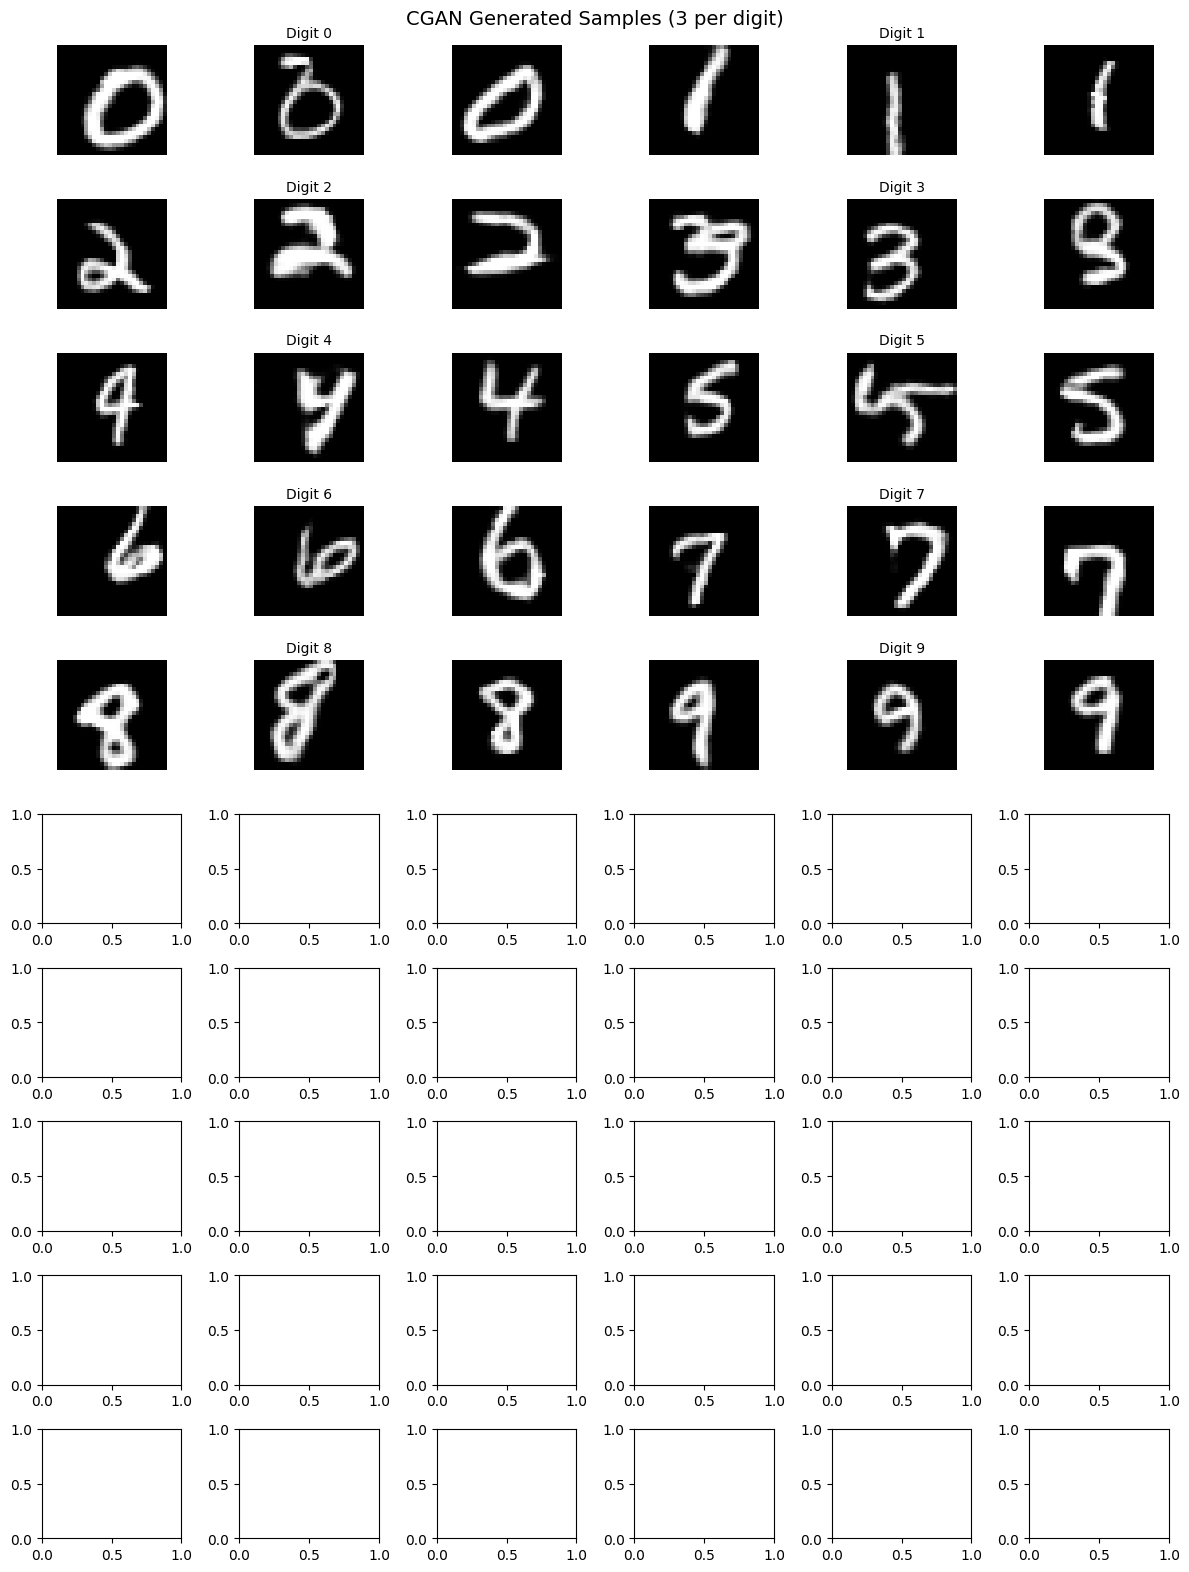

Generation time: 2.498s for 30 images
Training time was: 58.2 min on Kaggle GPU

Comment on quality:
- After 100 epochs on 350 samples/digit, digits should be recognisable
  but may appear slightly blurry or have minor distortions.
- Some digits (e.g. 1, 7) are typically cleaner than curved ones (e.g. 8, 9).
- Mode collapse would look like all rows producing the same shape — check for it.


In [11]:
# ============================================================
# Generate 3 samples per digit + comment
# ============================================================
def generate_and_show(generator, n_per_digit=3):
    gen_start = time.time()

    digits = list(range(10))

    fig, axes = plt.subplots(10, 6, figsize=(12, 16))

    for row in range(10):
        for group in range(2):  # 2 digits per row
            digit = row * 2 + group
            if digit >= 10:
                continue

            noise = tf.random.normal([n_per_digit, NOISE_DIM])
            labels = tf.constant([[digit]] * n_per_digit, dtype=tf.int32)

            imgs = generator([noise, labels], training=False).numpy()
            imgs = denormalize(imgs)

            for col in range(n_per_digit):
                ax = axes[row, group * 3 + col]
                ax.imshow(imgs[col, :, :, 0], cmap='gray')
                ax.axis('off')

                if col == 1:
                    ax.set_title(f"Digit {digit}", fontsize=10)

    plt.suptitle("CGAN Generated Samples (3 per digit)", fontsize=14)
    plt.tight_layout()
    plt.show()

    gen_time = time.time() - gen_start
    print(f"Generation time: {gen_time:.3f}s for {10 * n_per_digit} images")
    print(f"Training time was: {total_train_time/60:.1f} min on Kaggle GPU")
    print("\nComment on quality:")
    print("- After 100 epochs on 350 samples/digit, digits should be recognisable")
    print("  but may appear slightly blurry or have minor distortions.")
    print("- Some digits (e.g. 1, 7) are typically cleaner than curved ones (e.g. 8, 9).")
    print("- Mode collapse would look like all rows producing the same shape — check for it.")


generate_and_show(generator, n_per_digit=3)

In [33]:
test_images, test_labels = balanced_subsample(test_images_full, test_labels_full, 200)
test_images = test_images/255

In [34]:
from tensorflow.keras import layers, models
# ============================================================
# Helper: build + train classifier, return accuracy
# ============================================================
def build_classifier():
    model = models.Sequential([
        layers.Conv2D(6, (5,5), activation='relu', input_shape=(28,28,1)),
        layers.MaxPooling2D((2,2)),
        
        layers.Conv2D(16, (5,5), activation='relu'),
        layers.MaxPooling2D((2,2)),
        
        layers.Flatten(),
        
        layers.Dense(120, activation='relu'),
        layers.Dense(84, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

def train_and_evaluate(real_imgs, real_labs,
                       gen_imgs=None, gen_labs=None,
                       epochs=15, label=""):
    """Train classifier on real (+ optional synthetic) data, return test accuracy."""
    if gen_imgs is not None:
        X = np.concatenate([real_imgs, gen_imgs])[..., np.newaxis]
        y = np.concatenate([real_labs, gen_labs])
    else:
        X = real_imgs[..., np.newaxis]
        y = real_labs

    X = X.astype(np.float32)   # already [0,1]

    clf = build_classifier()
    t0  = time.time()
    clf.fit(X, y, epochs=epochs, batch_size=64, verbose=0)
    clf_time = time.time() - t0

    _, acc = clf.evaluate(test_images, test_labels, verbose=1)
    print(f"  {label:<50} | Acc: {acc*100:.2f}% | Time: {clf_time:.1f}s")
    return clf, acc

real_imgs, real_labs = balanced_subsample(train_images_full.astype(np.float32),train_labels_full,350)
real_imgs = real_imgs / 255.0

In [35]:
# Baseline: real data only
clf, acc = train_and_evaluate(
    real_imgs,
    real_labs,
    label=f"{350} real only"
)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9699 - loss: 0.1344
  350 real only                                      | Acc: 95.45% | Time: 6.1s


In [36]:
# ============================================================
# CELL 12 — NEW: Generate 5 runs × 1000 images per digit
# Then score with LeNet-5 and split into Set A / B / C
# ============================================================
def generate_one_run(generator, n_per_digit=1000):
    """One run: generate n_per_digit images for each digit."""
    all_imgs, all_labs = [], []
    for digit in range(10):
        noise  = tf.random.normal([n_per_digit, NOISE_DIM])
        labels = tf.constant([[digit]] * n_per_digit, dtype=tf.int32)
        imgs   = generator([noise, labels], training=False).numpy()
        imgs   = denormalize(imgs)[:, :, :, 0]   # (N,28,28) in [0,1]
        all_imgs.append(imgs)
        all_labs.append(np.full(n_per_digit, digit, dtype=np.int32))
    return np.vstack(all_imgs), np.hstack(all_labs)


def score_images(images, labels, scorer_model):
    """Return confidence = max(softmax) for each image."""
    X = images[..., np.newaxis].astype(np.float32)   # already [0,1]
    probs = scorer_model.predict(X, batch_size=256, verbose=0)
    confidence = np.max(probs, axis=1)
    return confidence


# --- 5 generation runs ---
N_RUNS       = 5
N_PER_DIGIT  = 1000

print(f"Generating {N_RUNS} runs × {N_PER_DIGIT} images/digit = "
      f"{N_RUNS * N_PER_DIGIT * 10} total GAN images...\n")

all_gen_imgs = []
all_gen_labs = []
all_gen_conf = []

gen_start = time.time()
for run in range(N_RUNS):
    imgs, labs = generate_one_run(generator, n_per_digit=N_PER_DIGIT)
    conf       = score_images(imgs, labs, clf)
    all_gen_imgs.append(imgs)
    all_gen_labs.append(labs)
    all_gen_conf.append(conf)
    print(f"  Run {run+1}: mean confidence = {conf.mean():.3f} | "
          f"high (≥0.9): {(conf>=0.9).sum()} | "
          f"mid (0.6-0.9): {((conf>=0.6)&(conf<0.9)).sum()}")

gen_time = time.time() - gen_start
print(f"\nTotal generation time: {gen_time:.1f}s")

# Pool all runs together
pool_imgs = np.vstack(all_gen_imgs)   # (50000, 28, 28)
pool_labs = np.hstack(all_gen_labs)
pool_conf = np.hstack(all_gen_conf)

print(f"\nTotal pooled: {pool_imgs.shape[0]} images")

Generating 5 runs × 1000 images/digit = 50000 total GAN images...

  Run 1: mean confidence = 0.879 | high (≥0.9): 6516 | mid (0.6-0.9): 2371
  Run 2: mean confidence = 0.875 | high (≥0.9): 6448 | mid (0.6-0.9): 2412
  Run 3: mean confidence = 0.875 | high (≥0.9): 6453 | mid (0.6-0.9): 2383
  Run 4: mean confidence = 0.878 | high (≥0.9): 6543 | mid (0.6-0.9): 2347
  Run 5: mean confidence = 0.874 | high (≥0.9): 6446 | mid (0.6-0.9): 2382

Total generation time: 3.8s

Total pooled: 50000 images


Set A (all):           50000 images
Set B (conf ≥ 0.9):    32406 images
Set C (0.6 ≤ c < 0.9): 11895 images


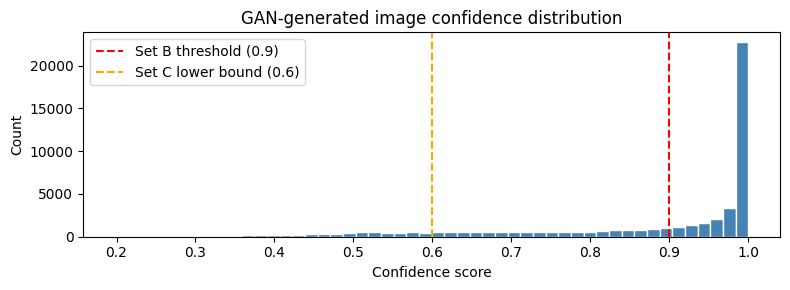

In [37]:
# ============================================================
# Create Set A, Set B, Set C
# ============================================================
# Set A — all generated samples
mask_A = np.ones(len(pool_imgs), dtype=bool)

# Set B — high confidence ≥ 0.9
mask_B = pool_conf >= 0.9

# Set C — mid confidence 0.6 ≤ conf < 0.9
mask_C = (pool_conf >= 0.6) & (pool_conf < 0.9)

set_A_imgs, set_A_labs = pool_imgs[mask_A], pool_labs[mask_A]
set_B_imgs, set_B_labs = pool_imgs[mask_B], pool_labs[mask_B]
set_C_imgs, set_C_labs = pool_imgs[mask_C], pool_labs[mask_C]

print(f"Set A (all):          {len(set_A_imgs):6d} images")
print(f"Set B (conf ≥ 0.9):   {len(set_B_imgs):6d} images")
print(f"Set C (0.6 ≤ c < 0.9):{len(set_C_imgs):6d} images")

# Quick confidence histogram
plt.figure(figsize=(8, 3))
plt.hist(pool_conf, bins=50, color='steelblue', edgecolor='white')
plt.axvline(0.9, color='red',    linestyle='--', label='Set B threshold (0.9)')
plt.axvline(0.6, color='orange', linestyle='--', label='Set C lower bound (0.6)')
plt.xlabel('Confidence score')
plt.ylabel('Count')
plt.title('GAN-generated image confidence distribution')
plt.legend()
plt.tight_layout()
plt.show()

In [38]:
# ============================================================
# CELL 15 — PART 2 Results Table
# Compares all configurations required by the assignment
# ============================================================
print("=" * 80)
print("PART 2 — GAN Synthetic Data Results")
print("=" * 80)
print(f"  {'Configuration':<55} | {'Accuracy':>8} | Time")
print("-" * 80)

results_gan = {}

# Baseline A: 350 real only
real_imgs1, real_labs1 = balanced_subsample(train_images_full.astype(np.float32),train_labels_full,350)
real_imgs1 = real_imgs1 / 255.0
acc = train_and_evaluate(real_imgs1, real_labs1,
                         label="Baseline: 350 real only")
results_gan['350_real_only'] = acc

# Baseline B: 1000 real only (gold standard)
real_imgs2, real_labs2 = balanced_subsample(train_images_full.astype(np.float32),train_labels_full,1000)
real_imgs2 = real_imgs2 / 255.0
acc = train_and_evaluate(real_imgs2,real_labs2 ,
                         label="Baseline: 1000 real only (gold standard)")
results_gan['1000_real_only'] = acc

# Set A — 350 real + ALL generated
acc = train_and_evaluate(real_imgs1, real_labs1,
                         set_A_imgs, set_A_labs,
                         label="350 real + Set A (all GAN)")
results_gan['350_SetA'] = acc

# Set B — 350 real + high-confidence only
acc = train_and_evaluate(real_imgs1,real_labs1 ,
                         set_B_imgs, set_B_labs,
                         label="350 real + Set B (conf ≥ 0.9)")
results_gan['350_SetB'] = acc

# Set C — 350 real + mid-confidence
acc = train_and_evaluate(real_imgs1,real_labs1 ,
                         set_C_imgs, set_C_labs,
                         label="350 real + Set C (0.6 ≤ conf < 0.9)")
results_gan['350_SetC'] = acc

PART 2 — GAN Synthetic Data Results
  Configuration                                           | Accuracy | Time
--------------------------------------------------------------------------------
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9669 - loss: 0.1138
  Baseline: 350 real only                            | Acc: 95.45% | Time: 6.2s
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9799 - loss: 0.0733
  Baseline: 1000 real only (gold standard)           | Acc: 97.25% | Time: 9.8s
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9816 - loss: 0.0856
  350 real + Set A (all GAN)                         | Acc: 97.30% | Time: 34.0s
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9793 - loss: 0.0986
  350 real + Set B (conf ≥ 0.9)                      | Acc: 96.75% | Time: 24.6s
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9818 - loss: 0.0912
  350 real + Set C (0.6 ≤ conf < 0.9)                | Acc: 97.20% | Time: 13.2s
